# SecondLook | 09 Borrower Personas

**Goal:** group the applicants the model does **not** approve (declined or under review) into a few recognisable types with **K-Means clustering**, so the dashboard can say *who* SecondLook helps and how.

**Unsupervised learning:** K-Means gets no labels. It places k centres and assigns each applicant to the nearest one, moving the centres until they settle. We then *read* each cluster's profile and give it a name a loan officer would recognise.

**Features (8, none sensitive):** average external score, loan vs income, repayment vs income, number of payments, years employed, share of past payments late, has a bureau record, number of past loans at other lenders. Age, gender and family features are **not** used; we check afterwards that they do not define a persona.

## 1. Setup and data

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

import lightgbm as lgb
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from secondlook.config import FIGURES_DIR, ID_COL, RANDOM_STATE, TARGET_COL
from secondlook import modeling as M
from secondlook import path as P
from secondlook.features import load_features

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

BUNDLE = ROOT / "app" / "demo_data"
meta = json.loads((BUNDLE / "model_meta.json").read_text())
port = pd.read_parquet(BUNDLE / "portfolio.parquet")
_, test = M.split(load_features())
assert (test[ID_COL].values == port[ID_COL].values).all()
test = test.assign(PD=port["PD_LGBM"].values)
not_approved = test[test["PD"] >= meta["cutoff"]].copy()

FEATURES = ["EXT_SOURCE_MEAN", "CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "CREDIT_TERM", "YEARS_EMPLOYED",
            "INST_LATE_SHARE", "HAS_BUREAU_HISTORY", "BUR_N_LOANS"]
X = not_approved[FEATURES]
print(f"{len(not_approved):,} test applicants not approved (PD >= {meta['cutoff']}); "
      f"{(not_approved['PD'] < meta['cutoff'] + 0.05).mean():.0%} of them are under review")
X.describe().T[["mean", "50%", "max"]].round(2)

7,263 test applicants not approved (PD >= 0.17); 36% of them are under review


,mean,50%,max
EXT_SOURCE_MEAN,0.31,0.31,0.84
CREDIT_TO_INCOME,3.73,3.21,84.74
ANNUITY_TO_INCOME,0.19,0.18,1.88
CREDIT_TERM,19.66,19.50,45.17
YEARS_EMPLOYED,3.99,2.78,34.39
INST_LATE_SHARE,0.12,0.07,1.00
HAS_BUREAU_HISTORY,0.79,1.00,1.00
BUR_N_LOANS,4.48,3.00,56.00


**Why impute and scale?** K-Means measures plain distances. Missing values have no distance, so we fill them with the median (few are missing: mostly late-payment share for people with no past loans here). Without scaling, a feature measured in large units (loan vs income reaches 20+, a yes/no flag is 0 or 1) would decide the clusters on its own. `StandardScaler` puts every feature on the same footing (mean 0, standard deviation 1). Both steps sit in one scikit-learn `Pipeline` with the K-Means model.

## 2. Choosing k: elbow plot and silhouette score

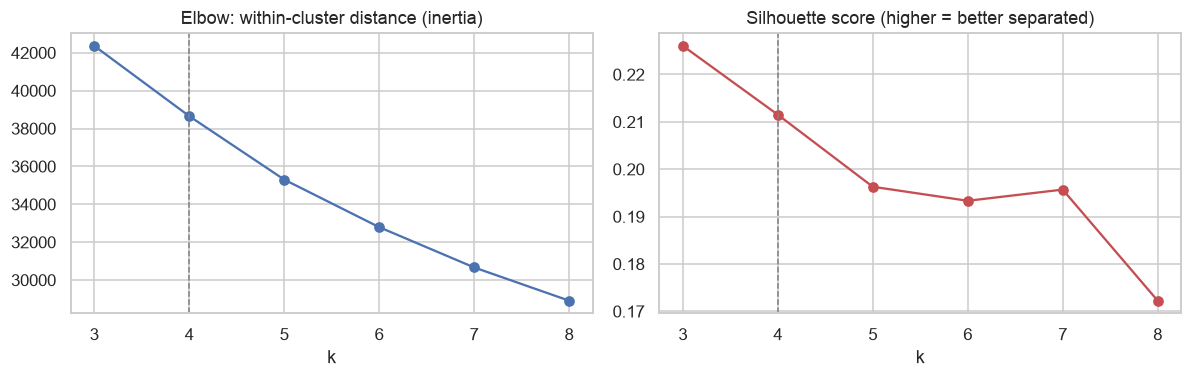

,inertia,silhouette,smallest cluster
k,,,
3,42363.871,0.226,1429
4,38654.570,0.212,963
5,35303.574,0.196,810
6,32792.570,0.193,418
7,30665.746,0.196,376
8,28910.820,0.172,301


In [2]:
def make_pipeline_k(k):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10))

rows = []
for k in range(3, 9):
    pipe = make_pipeline_k(k)
    labels = pipe.fit_predict(X)
    Z = pipe[:-1].transform(X)
    rows.append({"k": k, "inertia": pipe[-1].inertia_,
                 "silhouette": silhouette_score(Z, labels, sample_size=5000, random_state=RANDOM_STATE),
                 "smallest cluster": np.bincount(labels).min()})
choice = pd.DataFrame(rows).set_index("k")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
choice["inertia"].plot(marker="o", ax=axes[0], title="Elbow: within-cluster distance (inertia)")
choice["silhouette"].plot(marker="o", ax=axes[1], color="#C44E52", title="Silhouette score (higher = better separated)")
for ax in axes: ax.axvline(4, color="grey", ls="--", lw=1)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "30_persona_k.png", dpi=150, bbox_inches="tight"); plt.show()
choice.round(3)

**Choice: k = 4.** The elbow curve has no sharp bend; it flattens gradually between 3 and 5. The silhouette score is best at k = 3 (0.23) and almost as good at k = 4 (0.21), then drops. k = 4 keeps nearly the best separation and splits the large "typical" group, which gives one more persona an officer can act on (a loan that is large for the income). Above 5 the score falls and clusters get small. Silhouette scores around 0.2 also tell us honestly that these are **overlapping types, not sharply separate groups**.

## 3. Fit, profile and name the personas

In [3]:
K = 4
pipe = make_pipeline_k(K)
not_approved["cluster"] = pipe.fit_predict(X)

# Path to approval (notebook 06) for every not-approved applicant, re-scored with the app's model
booster = lgb.Booster(model_str=(BUNDLE / "model.txt").read_text())
paths = P.summarise(P.score_grid(not_approved, booster, meta), meta["cutoff"])
not_approved = not_approved.merge(paths[[ID_COL, "has_path"]], on=ID_COL, how="left")

profile = not_approved.groupby("cluster").agg(
    applicants=(ID_COL, "size"), repaid=(TARGET_COL, lambda t: 1 - t.mean()), has_path=("has_path", "mean"),
    under_review=("PD", lambda p: (p < meta["cutoff"] + 0.05).mean()), **{f: (f, "median") for f in FEATURES})
profile.round(2)

,applicants,repaid,has_path,under_review,EXT_SOURCE_MEAN,CREDIT_TO_INCOME,ANNUITY_TO_INCOME,CREDIT_TERM,YEARS_EMPLOYED,INST_LATE_SHARE,HAS_BUREAU_HISTORY,BUR_N_LOANS
cluster,,,,,,,,,,,,
0,963,0.71,0.54,0.37,0.32,3.12,0.15,20.459999,8.44,0.07,1.0,11.0
1,3686,0.71,0.51,0.34,0.31,2.67,0.16,18.309999,2.32,0.08,1.0,3.0
2,1396,0.72,0.54,0.36,0.29,3.16,0.19,18.360001,2.61,0.08,0.0,0.0
3,1218,0.72,0.55,0.41,0.32,6.68,0.27,27.840000,2.91,0.06,1.0,4.0


In [4]:
# Names come from each cluster's profile above, never from age or gender
NAMES = {
    0: "Established borrower",      # 8+ years in the job, about 11 past loans at other lenders
    1: "Newer worker, ordinary loan",  # about 2 years in the job, a few past loans, typical loan size
    2: "Thin file",                 # no credit bureau record at all
    3: "Stretched loan",            # loan about 6-7x income, repayments over a quarter of income, long term
}
assert profile.loc[2, "HAS_BUREAU_HISTORY"] == 0 and profile.loc[3, "CREDIT_TO_INCOME"] == profile["CREDIT_TO_INCOME"].max()
assert profile.loc[0, "YEARS_EMPLOYED"] == profile["YEARS_EMPLOYED"].max()
SENTENCE = {
    "Established borrower": "Long job tenure and a long credit record, declined mainly on external scores: a good fit for a second look.",
    "Newer worker, ordinary loan": "The largest group: a typical loan, but only about two years in the current job and a short credit record.",
    "Thin file": "No credit bureau record, so the model leans on external scores and the loan itself: SecondLook's core audience.",
    "Stretched loan": "The loan is large for the income; a smaller amount or longer term is the natural conversation.",
}
not_approved["persona"] = not_approved["cluster"].map(NAMES)
profile.index = profile.index.map(NAMES)
profile["sentence"] = profile.index.map(SENTENCE)
profile.drop(columns="sentence").style.format({"repaid": "{:.0%}", "has_path": "{:.0%}", "under_review": "{:.0%}",
    "EXT_SOURCE_MEAN": "{:.2f}", "CREDIT_TO_INCOME": "{:.1f}", "ANNUITY_TO_INCOME": "{:.2f}", "CREDIT_TERM": "{:.0f}",
    "YEARS_EMPLOYED": "{:.1f}", "INST_LATE_SHARE": "{:.0%}", "HAS_BUREAU_HISTORY": "{:.0f}", "BUR_N_LOANS": "{:.0f}"})

,applicants,repaid,has_path,under_review,EXT_SOURCE_MEAN,CREDIT_TO_INCOME,ANNUITY_TO_INCOME,CREDIT_TERM,YEARS_EMPLOYED,INST_LATE_SHARE,HAS_BUREAU_HISTORY,BUR_N_LOANS
cluster,,,,,,,,,,,,
Established borrower,963,71%,54%,37%,0.32,3.1,0.15,20,8.4,7%,1,11
"Newer worker, ordinary loan",3686,71%,51%,34%,0.31,2.7,0.16,18,2.3,8%,1,3
Thin file,1396,72%,54%,36%,0.29,3.2,0.19,18,2.6,8%,0,0
Stretched loan,1218,72%,55%,41%,0.32,6.7,0.27,28,2.9,6%,1,4


**Interpretation:** the four personas differ clearly on what *defines* them (bureau record, job tenure, loan size vs income), but **all four repay about 71–72% of the time** and about half of each has a realistic path to approval. That matters for the pitch: no persona is "the bad one". Every group of applicants the model turns away contains many good borrowers, which is the case for a human second look across the board, with a different conversation for each type.

## 4. Do age or gender drive the personas?

In [5]:
check = pd.DataFrame({
    "women": not_approved.groupby("persona")["CODE_GENDER"].apply(lambda g: (g == "F").mean()),
    "median age": not_approved.groupby("persona")["AGE_YEARS"].median(),
    "age 20s": not_approved.groupby("persona")["AGE_YEARS"].apply(lambda a: (a < 30).mean()),
    "age 50+": not_approved.groupby("persona")["AGE_YEARS"].apply(lambda a: (a >= 50).mean()),
})
check.loc["all not approved"] = [(not_approved["CODE_GENDER"] == "F").mean(), not_approved["AGE_YEARS"].median(),
                                 (not_approved["AGE_YEARS"] < 30).mean(), (not_approved["AGE_YEARS"] >= 50).mean()]
check.style.format({"women": "{:.0%}", "median age": "{:.0f}", "age 20s": "{:.0%}", "age 50+": "{:.0%}"})

,women,median age,age 20s,age 50+
persona,,,,
Established borrower,62%,41,9%,23%
"Newer worker, ordinary loan",51%,35,30%,14%
Stretched loan,68%,39,20%,22%
Thin file,49%,35,31%,12%
all not approved,55%,37,26%,16%


**Interpretation:** every persona contains both genders and every age group, so neither defines a persona. They are not spread *evenly*, though. "Established borrower" is older (median 41 vs 37 overall) because years in the current job and the length of a credit record naturally grow with age, and "Stretched loan" has more women. We name and describe personas only by the loan and credit features, and report this imbalance rather than hide it.

## 5. A 2D map with PCA

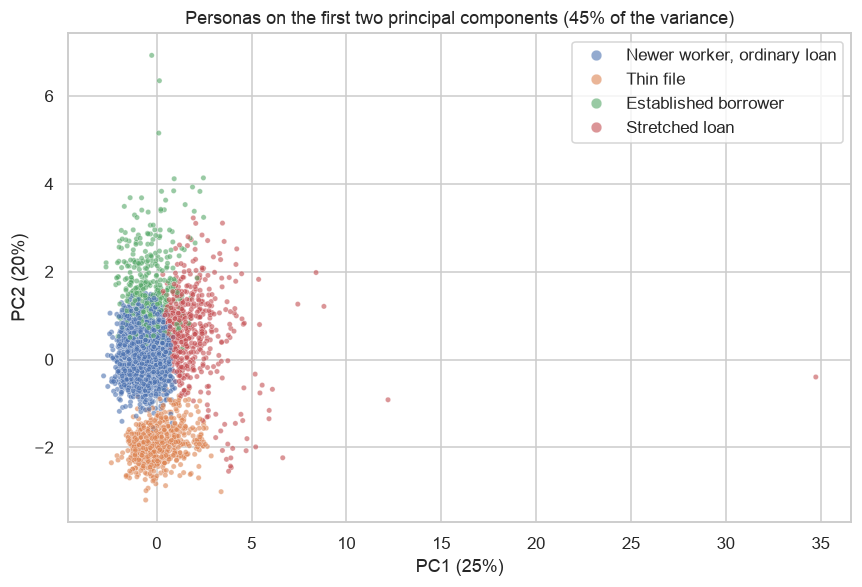

PC1 + PC2 explain 45% of the variance of the 8 scaled features


In [6]:
Z = pipe[:-1].transform(X)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
xy = pca.fit_transform(Z)
not_approved["pc1"], not_approved["pc2"] = xy[:, 0], xy[:, 1]
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=not_approved.sample(3000, random_state=1), x="pc1", y="pc2", hue="persona", s=12, alpha=0.6, ax=ax)
ev = pca.explained_variance_ratio_
ax.set(title=f"Personas on the first two principal components ({ev.sum():.0%} of the variance)",
       xlabel=f"PC1 ({ev[0]:.0%})", ylabel=f"PC2 ({ev[1]:.0%})")
ax.legend(markerscale=2, title=None)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "31_persona_map.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"PC1 + PC2 explain {ev.sum():.0%} of the variance of the 8 scaled features")

**Interpretation:** PCA squeezes the 8 scaled features into the 2 directions with the most variation, only to draw them. The two components keep under half of the information, so the clusters overlap on the map more than they do in 8 dimensions. Read the map as a picture of the types, not as proof of how separate they are.

## 6. Save a small persona table for the app

In [7]:
out = not_approved[[ID_COL, "persona", "pc1", "pc2", "has_path", "PD", TARGET_COL, "HAS_BUREAU_HISTORY"]].copy()
out[["pc1", "pc2", "PD"]] = out[["pc1", "pc2", "PD"]].astype("float32")
out.to_parquet(BUNDLE / "personas.parquet", index=False)
prof_out = profile.reset_index().rename(columns={"cluster": "persona"})
prof_out["pca_variance_explained"] = float(ev.sum())
prof_out.to_json(BUNDLE / "personas_profile.json", orient="records", indent=1)
print(f"Saved personas.parquet ({(BUNDLE / 'personas.parquet').stat().st_size / 1e3:.0f} KB) and personas_profile.json")

Saved personas.parquet (173 KB) and personas_profile.json


## Takeaways

1. **7,263 test applicants are not approved** (36% of them under review). K-Means on 8 non-sensitive features, with k = 4 chosen from the elbow plot and the silhouette score (0.21, close to the best 0.23 at k = 3), groups them into four personas:

| Persona | Applicants | What defines it | Repaid | Path to approval |
|---|---|---|---|---|
| Established borrower | 963 | 8+ years in the job, about 11 past loans elsewhere | 71% | 54% |
| Newer worker, ordinary loan | 3,686 | about 2 years in the job, a few past loans | 71% | 51% |
| Thin file | 1,396 | no credit bureau record | 72% | 54% |
| Stretched loan | 1,218 | loan about 6.7× income, long term | 72% | 55% |

2. **No persona is "the bad one".** Every type repays about 71–72% of the time and about half has a realistic path to approval: there are good borrowers to find in every group the model turns away.
3. **Each persona suggests a different conversation:** a second look at external scores for established borrowers, a smaller loan or longer term for stretched loans, and the thin-file group is SecondLook's core audience.
4. **Age and gender do not define any persona**, but they are not spread evenly: established borrowers are older (median 41 vs 37) because tenure and credit history grow with age. Names describe loans and credit records only.
5. **The clusters overlap** (silhouette about 0.2; the 2D PCA map keeps 45% of the variance): treat personas as helpful types for officers, not as sharp segments.